# Lab 3 — Get started with Hugging Face
**Học phần Deep Learning · GV: TS. Nguyễn Thị Khánh Tiên**

Hoàn thành Exercise 1 và Exercise 2 ở slide Chương 4, trang 25.
Notebook điều phối, logic tái sử dụng nằm trong `going_modular/`.

**Cách dùng:** giải nén toàn bộ ZIP, mở notebook này. Trên Colab, upload notebook rồi chạy cell setup và chọn ZIP khi được yêu cầu.
Chọn GPU trong Runtime → Change runtime type. Lần đầu cần Internet để cài thư viện, tải weights và IMDb.

| Phần | Nội dung | Đầu ra |
|---|---|---|
| 0 | Môi trường, cấu hình | Đường dẫn và phiên bản |
| 1 | Pretrained sentiment, tokenize, inference | Bảng token và dự đoán |
| 2 | IMDb và chia tập | Train/validation/test, thống kê nhãn |
| 3 | Tokenizer, padding, model | Batch input_ids/mask và logits |
| 4 | TrainingArguments, Trainer | Best checkpoint và history |
| 5 | Test và phân tích lỗi | Metrics, confusion matrix, CSV |
| 6 | Lưu/nạp và báo cáo | REPORT.md, model/tokenizer |

**Trạng thái:** notebook chính chưa chứa kết quả huấn luyện giả định. Xem `reports/VALIDATION.md` để biết những gì đã kiểm chứng khi giao bài.


**Bản đã thực thi:** quick, dữ liệu IMDb thật, 2.000 train / 500 validation / 1.000 test, 2 epochs. Kết quả thực tế nằm trong các outputs bên dưới. Dùng notebook không có hậu tố `_executed` nếu muốn bắt đầu chạy mới.


## 0. Thiết lập môi trường và đường dẫn


In [1]:
from pathlib import Path
import sys, subprocess, zipfile
IS_COLAB = 'google.colab' in sys.modules
try:
    import google.colab
    IS_COLAB = True
except ImportError:
    pass
candidates = [Path.cwd(), Path.cwd().parent, Path('/content/lab3')]
ROOT = next((p for p in candidates if (p/'going_modular/config.py').is_file() and (p/'requirements.txt').is_file()), None)
if ROOT is None and IS_COLAB:
    from google.colab import files
    print('Chọn file ZIP Lab 3 được cung cấp (toàn bộ project).')
    uploaded = files.upload()
    zip_name = next(name for name in uploaded if name.endswith('.zip'))
    destination = Path('/content').resolve()
    with zipfile.ZipFile(zip_name) as archive:
        for item in archive.infolist():
            target = (destination/item.filename).resolve()
            if not target.is_relative_to(destination):
                raise ValueError('ZIP chứa đường dẫn không hợp lệ.')
        archive.extractall(destination)
    ROOT = destination/'lab3'
if ROOT is None or not (ROOT/'going_modular/config.py').is_file():
    raise FileNotFoundError('Giải nén toàn bộ project và mở notebook trong lab3/notebooks/.')
ROOT = ROOT.resolve()
sys.path.insert(0, str(ROOT))
print('Project:', ROOT)


Project: /workspace/scratch/38d5f9cfc17c/lab3


In [2]:
# Cài đúng bộ thư viện. Sau khi đổi phiên bản trong runtime đã import thư viện, restart kernel.
INSTALL_DEPENDENCIES = IS_COLAB
if INSTALL_DEPENDENCIES:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT/'requirements.txt')])
else:
    print('Local: cài requirements.txt trong terminal trước, chọn đúng kernel .venv.')


Local: cài requirements.txt trong terminal trước, chọn đúng kernel .venv.


In [3]:
import torch
import pandas as pd
from IPython.display import display, Image
from going_modular import RunConfig, SENTIMENT_MODEL
from going_modular import data_setup, model_builder, engine, evaluate, utils, reporting

USE_DRIVE = IS_COLAB
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK_ROOT = Path('/content/drive/MyDrive/lab3')
else:
    WORK_ROOT = ROOT
ARTIFACT_ROOT = WORK_ROOT/'artifacts'
OUTPUT_ROOT = WORK_ROOT/'outputs'
LOG_ROOT = WORK_ROOT/'logs'
PROFILE = 'quick'           # 'quick' hoặc 'full'; full cho kết quả trên toàn bộ test IMDb
ACTION = 'train'            # 'train', 'resume', 'reuse'; không tự xóa run cũ
CFG = RunConfig.for_profile(PROFILE)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
utils.seed_everything(CFG.seed)
print(CFG)
print(utils.environment_info())
print('Artifacts:', ARTIFACT_ROOT)


RunConfig(run_id='distilbert_imdb_quick', model_id='distilbert/distilbert-base-uncased', model_revision='main', dataset_id='stanfordnlp/imdb', dataset_revision='main', profile='quick', seed=42, val_size=5000, train_limit=2000, val_limit=500, test_limit=1000, max_length=128, epochs=2, batch_size=16, eval_batch_size=32, learning_rate=2e-05, weight_decay=0.01, warmup_ratio=0.1, gradient_accumulation_steps=1, max_grad_norm=1.0)
{'python': '3.12.14', 'cuda_available': False, 'device': 'CPU', 'torch': '2.15.0+cpu', 'transformers': '4.57.1', 'datasets': '4.3.0', 'evaluate': '0.4.6', 'accelerate': '1.11.0', 'numpy': '2.5.4', 'scikit-learn': '1.9.1'}
Artifacts: /workspace/scratch/38d5f9cfc17c/lab3/artifacts


## 1. Exercise 1 — Sentiment Analysis with Hugging Face
Checkpoint SST-2 đã học phân loại cảm xúc tiếng Anh. Bài này chỉ suy luận, không cập nhật weights.
`AutoTokenizer` biến chuỗi thành token IDs và attention mask; model trả hai logits;
softmax biến logits thành phân phối hai lớp, argmax chọn nhãn.

Không dùng checkpoint SST-2 làm điểm khởi tạo Exercise 2: bài 2 dùng DistilBERT nền và head mới,
để thấy rõ quá trình fine-tune trên IMDb. Hai checkpoint có mục đích khác nhau.


In [4]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline
EX1_REVISION = 'main'  # Có thể thay bằng commit SHA trên Hub để cố định phiên bản.
sent_tokenizer = AutoTokenizer.from_pretrained(SENTIMENT_MODEL, revision=EX1_REVISION)
sent_model = AutoModelForSequenceClassification.from_pretrained(SENTIMENT_MODEL, revision=EX1_REVISION).to(DEVICE)
sample = 'I really enjoyed this movie. The acting was wonderful!'
encoded = sent_tokenizer(sample, return_tensors='pt')
display(pd.DataFrame({'token': sent_tokenizer.convert_ids_to_tokens(encoded['input_ids'][0].tolist()),
                      'input_id': encoded['input_ids'][0].tolist(),
                      'attention_mask': encoded['attention_mask'][0].tolist()}))
sent_model.eval()
with torch.inference_mode():
    logits = sent_model(**{k:v.to(DEVICE) for k,v in encoded.items()}).logits
print('Logits:', logits.cpu())
print('Probabilities:', logits.softmax(-1).cpu())
print('Label map:', sent_model.config.id2label)


Logits: tensor([[-4.3383,  4.6716]])
Probabilities: tensor([[1.2218e-04, 9.9988e-01]])
Label map: {0: 'NEGATIVE', 1: 'POSITIVE'}


,token,input_id,attention_mask
0,[CLS],101,1
1,i,1045,1
2,really,2428,1
3,enjoyed,5632,1
4,this,2023,1
5,movie,3185,1
6,.,1012,1
7,the,1996,1
8,acting,3772,1
9,was,2001,1


In [5]:
sentences = [sample, 'The plot was boring and the dialogue was terrible.',
             'The movie was not bad at all.', 'Great actors, but I disliked the ending.']
manual_predictions = evaluate.predict_texts(sent_model, sent_tokenizer, sentences, max_length=CFG.max_length)
sentiment_pipeline = pipeline('sentiment-analysis', model=sent_model, tokenizer=sent_tokenizer,
                              device=0 if DEVICE.type == 'cuda' else -1)
pipeline_predictions = sentiment_pipeline(sentences, truncation=True, max_length=CFG.max_length)
display(pd.DataFrame(manual_predictions))
print('Pipeline:', pipeline_predictions)
EX1_OUTPUT = utils.new_output_dir(OUTPUT_ROOT, 'exercise1_pretrained')
utils.save_json(EX1_OUTPUT/'predictions.json', {'model':SENTIMENT_MODEL,
    'revision':getattr(sent_model.config, '_commit_hash', None),
    'manual':manual_predictions, 'pipeline':pipeline_predictions})
print('Đã lưu:', EX1_OUTPUT)
# Giải phóng GPU trước fine-tuning.
del sentiment_pipeline, sent_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Pipeline: [{'label': 'POSITIVE', 'score': 0.9998778104782104}, {'label': 'NEGATIVE', 'score': 0.9998095631599426}, {'label': 'POSITIVE', 'score': 0.9979925155639648}, {'label': 'NEGATIVE', 'score': 0.9869480133056641}]
Đã lưu: /workspace/scratch/38d5f9cfc17c/lab3/outputs/2026-11-11/exercise1_pretrained/181811-576123


,text,label_id,label,confidence,p_positive
0,I really enjoyed this movie. The acting was wo...,1,POSITIVE,0.999878,0.999878
1,The plot was boring and the dialogue was terri...,0,NEGATIVE,0.999810,0.000190
2,The movie was not bad at all.,1,POSITIVE,0.997993,0.997993
3,"Great actors, but I disliked the ending.",0,NEGATIVE,0.986948,0.013052


### Giải thích Exercise 1
- Token đặc biệt `[CLS]`, `[SEP]` đánh dấu cấu trúc; padding sẽ có mask bằng 0.
- Tokenizer có thể tách một từ thành nhiều subword; token không đồng nghĩa một từ hoàn chỉnh.
- Hai câu cuối dùng kiểm tra phủ định/cảm xúc pha trộn, không phải test set để báo cáo accuracy.
- Softmax confidence cao vẫn có thể dự đoán sai. Mô hình không có lớp trung tính.

## 2. Exercise 2 — Chuẩn bị IMDb
IMDb: 25.000 train và 25.000 test có nhãn. Chỉ tách validation từ train.
Full: 20.000/5.000/25.000. Quick: tập con phân tầng 2.000/500/1.000, lấy sau khi chia.
Không dùng tập `unsupervised`; nhãn Positive=1, Negative=0.


In [6]:
raw_splits = data_setup.load_imdb(CFG, cache_dir=str(ROOT/'cache'))
manifest = data_setup.split_manifest(raw_splits)
summary = [{ 'split':k, 'size':manifest[k]['size'], **manifest[k]['labels'] }
           for k in ('train','validation','test')]
display(pd.DataFrame(summary))
print('Exact-text overlap:', manifest['duplicate_text_overlap'])
print('Ví dụ TRAIN:', raw_splits['train'][0]['text'][:500])
# Không dùng nội dung/nhãn test để chọn hyperparameter.


Exact-text overlap: {'train__validation': 0, 'train__test': 0, 'validation__test': 0}
Ví dụ TRAIN: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself. The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to mak



Generating train split: 100%|##########| 25000/25000 [00:00<00:00, 72140.26 examples/s]

Generating test split: 100%|##########| 25000/25000 [00:00<00:00, 154171.29 examples/s]

Generating unsupervised split: 100%|##########| 50000/50000 [00:00<00:00, 111437.48 examples/s]

Map: 100%|##########| 2000/2000 [00:00<00:00, 8250.23 examples/s]

Map: 100%|##########| 500/500 [00:00<00:00, 8105.37 examples/s]

Map: 100%|##########| 1000/1000 [00:00<00:00, 8413.82 examples/s]


,split,size,0,1
0,train,2000,1000,1000
1,validation,500,250,250
2,test,1000,500,500


## 3. Tokenization, dynamic padding và model
Chỉ thay HTML line-break bằng khoảng trắng, giữ dấu câu/phủ định/thứ tự từ.
Tokenizer của model thực hiện lowercasing/subword; không stemming hay bỏ stopwords.
Truncation giới hạn số token. Dynamic padding đệm đến chuỗi dài nhất **trong batch**, tiết kiệm RAM.
Model nhận `input_ids`, `attention_mask`, `labels`; logits có shape `[batch, 2]`.


In [7]:
tokenizer = model_builder.load_tokenizer(CFG.model_id, CFG.model_revision)
tokenized = data_setup.tokenize_splits(raw_splits, tokenizer, CFG.max_length)
from transformers import DataCollatorWithPadding
collator = DataCollatorWithPadding(tokenizer=tokenizer)
batch = collator([tokenized['train'][i] for i in range(3)])
print({k: tuple(v.shape) for k,v in batch.items()})
assert set(batch['labels'].tolist()) <= {0,1}
assert batch['input_ids'].shape == batch['attention_mask'].shape
print('Length range:', min(map(len,tokenized['train']['input_ids'])), max(map(len,tokenized['train']['input_ids'])))


{'labels': (3,), 'input_ids': (3, 128), 'attention_mask': (3, 128)}
Length range: 15 128



Map: 100%|##########| 2000/2000 [00:01<00:00, 1257.10 examples/s]

Map: 100%|##########| 500/500 [00:00<00:00, 1469.71 examples/s]

Map: 100%|##########| 1000/1000 [00:00<00:00, 1380.10 examples/s]


## 4. TrainingArguments và Trainer
Đề yêu cầu `Trainer`, vì vậy không sao chép vòng lặp `loss.backward()` từ Lab 2.
Trong `engine.py`, TrainingArguments cấu hình AdamW, LR, batch, epochs, warmup,
linear scheduler, gradient clipping, validation/checkpoint theo epoch và TensorBoard.

- Fine-tune toàn bộ DistilBERT; head phân loại khởi tạo mới (cảnh báo head mới là bình thường).
- F1 lớp Positive trên validation chọn checkpoint tốt nhất; Trainer nạp lại checkpoint đó cuối train.
- `train`: chỉ chạy vào thư mục trống. `resume`: tiếp tục checkpoint của cùng cấu hình.
- `reuse`: nạp `best_model/`, không gọi `trainer.train()`.
- Full có thể tốn thời gian; quick dùng kiểm tra luồng, không báo cáo là kết quả toàn bộ IMDb.


In [8]:
# Hiển thị các TrainingArguments trước khi chạy.
args_preview = engine.make_training_args(CFG, ARTIFACT_ROOT/CFG.run_id, LOG_ROOT/CFG.run_id)
print({k:getattr(args_preview,k) for k in ['learning_rate','num_train_epochs',
 'per_device_train_batch_size','eval_strategy','save_strategy','metric_for_best_model',
 'lr_scheduler_type','warmup_ratio','max_grad_norm']})
trainer, history, RUN_DIR = engine.run_experiment(
    CFG, tokenized, tokenizer, manifest, ARTIFACT_ROOT, LOG_ROOT, action=ACTION)
print('Tham số:', model_builder.count_params(trainer.model))
print('Hoàn tất:', utils.read_json(RUN_DIR/'completed.json'))


{'learning_rate': 2e-05, 'num_train_epochs': 2, 'per_device_train_batch_size': 16, 'eval_strategy': <IntervalStrategy.EPOCH: 'epoch'>, 'save_strategy': <SaveStrategy.EPOCH: 'epoch'>, 'metric_for_best_model': 'f1', 'lr_scheduler_type': <SchedulerType.LINEAR: 'linear'>, 'warmup_ratio': 0.1, 'max_grad_norm': 1.0}
{'loss': 0.6984, 'grad_norm': 1.1235500574111938, 'learning_rate': 0.0, 'epoch': 0.01}
{'loss': 0.6897, 'grad_norm': 1.0189335346221924, 'learning_rate': 7.2000000000000005e-06, 'epoch': 0.08}
{'loss': 0.6959, 'grad_norm': 1.0439246892929077, 'learning_rate': 1.5200000000000002e-05, 'epoch': 0.16}
{'loss': 0.6958, 'grad_norm': 2.9135522842407227, 'learning_rate': 1.9644444444444447e-05, 'epoch': 0.24}
{'loss': 0.6787, 'grad_norm': 1.8634306192398071, 'learning_rate': 1.8755555555555558e-05, 'epoch': 0.32}
{'loss': 0.6629, 'grad_norm': 1.584399700164795, 'learning_rate': 1.7866666666666666e-05, 'epoch': 0.4}
{'loss': 0.618, 'grad_norm': 3.243624448776245, 'learning_rate': 1.697777


  0%|          | 1/250 [00:05<22:49,  5.50s/it]
                                               

  4%|4         | 10/250 [00:35<13:07,  3.28s/it]
                                                

  8%|8         | 20/250 [01:04<12:25,  3.24s/it]
                                                

 12%|#2        | 30/250 [01:33<09:43,  2.65s/it]
                                                

 16%|#6        | 40/250 [02:08<12:38,  3.61s/it]
                                                

 20%|##        | 50/250 [02:42<11:17,  3.39s/it]
                                                

 24%|##4       | 60/250 [03:15<10:34,  3.34s/it]
                                                

 28%|##8       | 70/250 [03:50<10:16,  3.43s/it]
                                                

 32%|###2      | 80/250 [04:22<09:06,  3.21s/it]
                                                

 36%|###6      | 90/250 [04:57<09:19,  3.50s/it]
                                                

 40%|####  

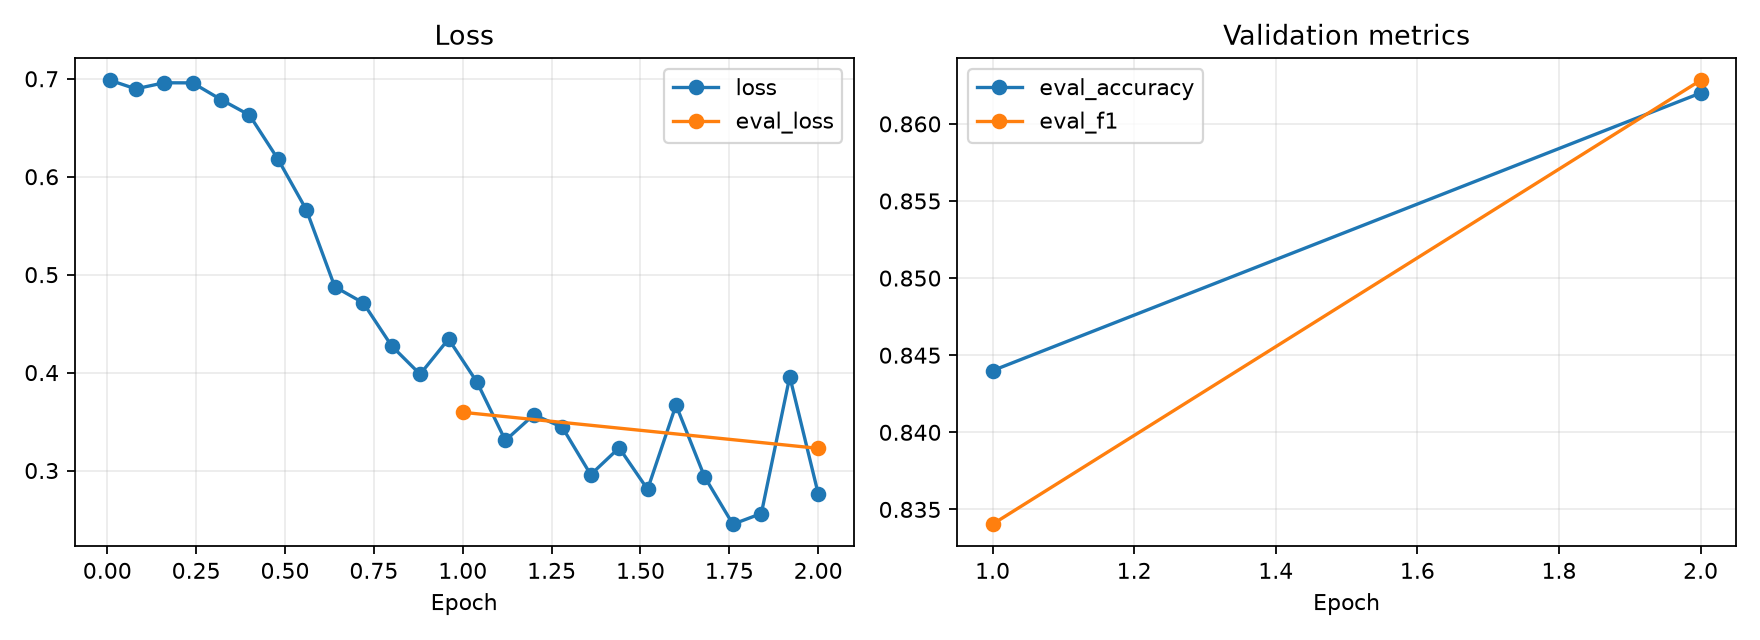

,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_f1,eval_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch,step
0,0.359438,0.844,0.890909,0.784,0.834043,0.843436,21.6467,23.098,0.739,1.0,125
1,0.322663,0.862,0.857708,0.868,0.862823,0.861995,13.4018,37.308,1.194,2.0,250


In [9]:
EVAL_DIR = utils.new_output_dir(OUTPUT_ROOT, CFG.run_id)
evaluate.plot_history(history, EVAL_DIR/'history.png')
display(Image(filename=str(EVAL_DIR/'history.png')))
display(pd.DataFrame([row for row in history if 'eval_f1' in row]))
# TensorBoard: chạy cell riêng %load_ext tensorboard rồi %tensorboard --logdir <LOG_ROOT>


## 5. Đánh giá test cuối và phân tích lỗi
Chỉ chạy sau khi cấu hình đã chốt. Không chọn epoch/LR dựa trên test.
Metrics: accuracy, precision/recall/F1 (Positive), macro F1, ROC-AUC và confusion matrix.
CSV giữ nguyên thứ tự sample_id để đối chiếu lỗi. Chỉ một lượt `Trainer.predict` cho test.



100%|##########| 32/32 [00:41<00:00,  1.31s/it]


,num_samples,accuracy,precision,recall,f1,macro_f1,roc_auc
0,1000,0.862,0.867886,0.854,0.860887,0.861991,0.931748


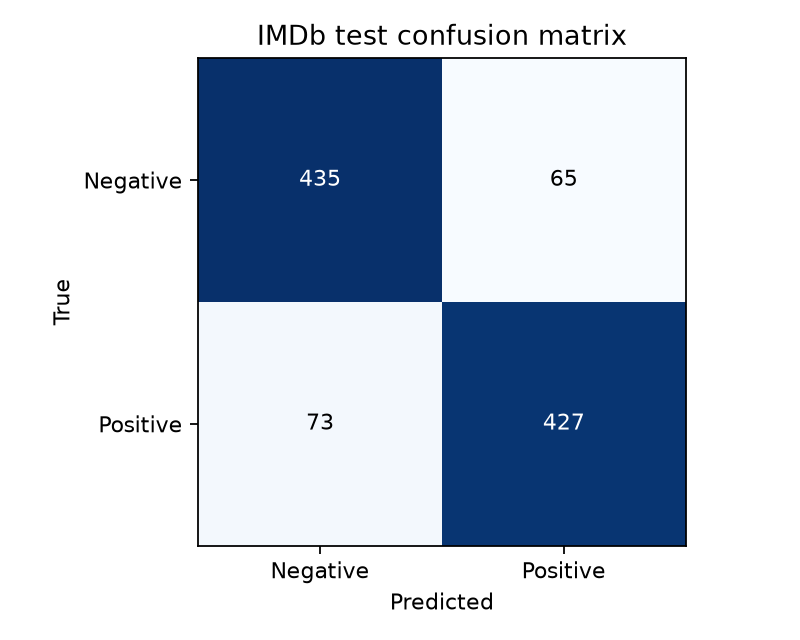

,text,y_true,y_pred,confidence
0,I enjoyed the beautiful scenery in this movie ...,0,1,0.961324
1,Personally I've watched it because of Lea Thom...,0,1,0.958288
2,"After seeing Forever Hollywood, it would be na...",0,1,0.955246
3,There's not much anyone can say about this fli...,1,0,0.954577
4,I really liked this quirky movie. The characte...,0,1,0.953764
5,"As many know, this is the feature film debut o...",0,1,0.952941
6,"As powerful as the true story of Phoolan is, t...",0,1,0.950228
7,"When I was young, I was a big fan of Chuck Nor...",0,1,0.949186
8,"First of all, I would like to clarify that I c...",0,1,0.943639
9,I swore I would never allow myself to devolve ...,1,0,0.942482


In [10]:
prediction = trainer.predict(tokenized['test'], metric_key_prefix='test')
metrics = evaluate.export_evaluation(prediction, raw_splits['test'], EVAL_DIR,
    metadata={'run_id':CFG.run_id,'profile':CFG.profile,'config':CFG.to_dict(),
              'data_sha256':utils.digest(manifest),
              'duplicate_text_overlap':manifest['duplicate_text_overlap']})
display(pd.DataFrame([{k:metrics[k] for k in ['num_samples','accuracy','precision','recall','f1','macro_f1','roc_auc']}]))
display(Image(filename=str(EVAL_DIR/'confusion_matrix.png')))
errors = pd.read_csv(EVAL_DIR/'errors.csv')
display(errors[['text','y_true','y_pred','confidence']].head(10))


### Cách nhận xét kết quả
1. So sánh train loss và validation loss; không kết luận overfitting chỉ từ một chỉ số.
2. Đọc ô FP/FN: FP = tiêu cực nhưng dự đoán tích cực; FN = tích cực nhưng dự đoán tiêu cực.
3. Đọc `errors.csv`, phân loại lỗi phủ định, mỉa mai, review pha trộn, hoặc thông tin bị truncation.
4. Tăng epochs/LR chỉ là giả thuyết thử nghiệm trên validation; test giữ lại để đánh giá cuối.
5. Không so accuracy từ model card SST-2 với test IMDb rồi kết luận fine-tune tốt/xấu hơn.

## 6. Lưu/nạp và suy luận văn bản mới
`best_model/` chứa cả weights, config và tokenizer. Tokenizer cần được lưu cùng model.


In [11]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
reloaded_tokenizer = AutoTokenizer.from_pretrained(RUN_DIR/'best_model')
reloaded_model = AutoModelForSequenceClassification.from_pretrained(RUN_DIR/'best_model').to(DEVICE)
new_reviews = ['A moving story with excellent performances.', 'I regret spending time on this dull movie.']
before = evaluate.predict_texts(trainer.model, tokenizer, new_reviews, CFG.max_length)
after = evaluate.predict_texts(reloaded_model, reloaded_tokenizer, new_reviews, CFG.max_length)
import numpy as np
assert np.allclose([x['p_positive'] for x in before], [x['p_positive'] for x in after], atol=1e-6)
display(pd.DataFrame(after))
utils.save_json(EVAL_DIR/'new_review_predictions.json',after)
del reloaded_model
report_path = reporting.write_report(EVAL_DIR, CFG, metrics, history, utils.read_json(RUN_DIR/'completed.json'))
print('Báo cáo sinh từ số liệu thực:', report_path)
print(report_path.read_text(encoding='utf-8'))


Báo cáo sinh từ số liệu thực: /workspace/scratch/38d5f9cfc17c/lab3/outputs/2026-11-11/distilbert_imdb_quick/183159-290735/REPORT.md
# Báo cáo kết quả Lab 3 — distilbert_imdb_quick

## 1. Mục tiêu và phương pháp
Fine-tune distilbert/distilbert-base-uncased cho phân loại cảm xúc IMDb. Nhãn 0 = NEGATIVE, 1 = POSITIVE.
Đầu vào là văn bản; tokenizer tạo input_ids và attention_mask; model tạo hai logits.
Trainer tối ưu cross-entropy bằng AdamW và linear scheduler có warmup.
Chọn checkpoint theo F1 lớp Positive trên validation; test chỉ chạy sau khi chốt model.

## 2. Cấu hình thực nghiệm
- Profile: **quick**. Kết quả chỉ đại diện tập test thực sự đã dùng.
- Seed: 42; max_length: 128; epochs yêu cầu: 2.
- Learning rate: 2e-05; batch: 16; weight decay: 0.01.
- Số bước optimizer hoàn thành: 250.
- F1 validation tốt nhất: 0.8628.
- Exact-text overlap giữa các split: {'train__validation': 0, 'train__test': 0, 'validation__test': 0}. Đây là chẩn đoán, không sửa benchmark dựa vào test.

## 3. Kết q

,text,label_id,label,confidence,p_positive
0,A moving story with excellent performances.,1,POSITIVE,0.930526,0.930526
1,I regret spending time on this dull movie.,0,NEGATIVE,0.875602,0.124398


## 7. Đối chiếu yêu cầu và kết luận
| Yêu cầu slide | Cell/phần đáp ứng |
|---|---|
| Cài transformers | 0 |
| Pretrained sentiment model | 1 |
| Tokenize câu mẫu | 1, bảng token/input_id/mask |
| Phân tích cảm xúc | 1, manual và pipeline |
| Cài transformers/datasets/evaluate | requirements và 0 |
| Load dataset nhị phân | 2 |
| Load model và tokenizer | 3–4 |
| Preprocess dataset | 2–3 |
| Training arguments | 4, make_training_args |
| Tạo Trainer và fine-tune | 4, run_experiment |
| Evaluate fine-tuned model | 5–6 |

`evaluate` được cài đúng đề; độ đo chính tính bằng sklearn để không phụ thuộc tải metric script từ Hub.
Các bước cuối chỉ hoàn tất khi bạn chạy notebook với dữ liệu/model thật; không xem unit test là kết quả học máy.

### Tài liệu tham khảo
- Slide Chương 4, trang 25; Chương 3: training/validation, TensorBoard, transfer learning.
- François Chollet, *Deep Learning with Python* (2018), §3.4, §4.2, §5.3, §6.1.
- Nguyễn Thanh Tuấn, *Deep Learning cơ bản*, bản 2, chương 11, 16–19.
- https://huggingface.co/docs/transformers/tasks/sequence_classification
- https://huggingface.co/docs/transformers/main_classes/trainer
- https://huggingface.co/datasets/stanfordnlp/imdb
- https://github.com/toan58936/lab2/tree/93d255b/going_modular
